# Deliberation allocation: beyond the state of the art

**Level:** 4  
**Prerequisites:** Deliberation allocation levels 1–3  
**Reading time:** 35 minutes

**Question:** Does resource-versioned M12 improve the success-cost frontier, and which parts of that claim survive the evidence?


## Objectives

Trace the BS-1 proposal from its executable components to the benchmark outcomes. Separate task success, safety properties, controller latency, and evidence scope. Identify a follow-up experiment that could falsify the proposal without changing its evaluation after seeing results.


## Setup

The pinned environment is recorded in `notebooks/requirements.txt`. Install exactly these versions before running the notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


## Data

The lesson reads the committed core index, the derived research summary, and the frozen M11/M12 C13 traces. These artifacts represent an authored software-operations benchmark, not naturalistic human behavior. The index hash is checked before records are compared. Failures remain in each denominator, and transfer evidence remains separate from the core matrix.


## Method

Recompute the recorded policy comparison from canonical artifacts, then inspect the executable package interface used to create and evaluate policies. A replayed record is evidence about the recorded run; a fresh episode is a separate measurement. Neither establishes generalization beyond these cases.


### Evidence analysis 1

Verify the index digest before reading the experiment, so any changed source data invalidates this analysis. This is evidence slice 1 in the deliberation study. Observation 1 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 1 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


### Evidence analysis 2

Select the matched C13 records only after the case, method, variant, and seed are explicit. This is evidence slice 2 in the deliberation study. Observation 2 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 2 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M11", "M12", "M09", "M10"]
trace_methods = ["M11", "M12", "M09", "M10", "M04"]
sample_case = "C13"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 5


### Evidence analysis 3

Reconstruct the paired observations from trace files instead of trusting a precomputed chart. This is evidence slice 3 in the deliberation study. Observation 3 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 3 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M09 boundary successes= 1 episodes= 10 rate= 0.1
M09 delayed_observation successes= 2 episodes= 10 rate= 0.2
M09 duplicate_event successes= 5 episodes= 10 rate= 0.5
M09 nominal successes= 4 episodes= 10 rate= 0.4
M09 stale_conflict successes= 2 episodes= 10 rate= 0.2
M09 unavailable_dependency successes= 3 episodes= 10 rate= 0.3
M10 boundary successes= 10 episodes= 10 rate= 1.0
M10 delayed_observation successes= 10 episodes= 10 rate= 1.0
M10 duplicate_event successes= 10 episodes= 10 rate= 1.0
M10 nominal successes= 10 episodes= 10 rate= 1.0
M10 stale_conflict successes= 10 episodes= 10 rate= 1.0
M10 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M11 boundary successes= 10 episodes= 10 rate= 1.0
M11 delayed_observation successes= 10 episodes= 10 rate= 1.0
M11 duplicate_event successes= 10 episodes= 10 rate= 1.0
M11 nominal successes= 10 episodes= 10 rate= 1.0
M11 stale_conflict successes= 10 episodes= 10 rate= 1.0
M11 unavailable_dependency successes= 10 episodes= 10 rate=

### Evidence analysis 4

Keep cancellation outcomes in the numerator and denominator; dropping them would conceal the principal failure. This is evidence slice 4 in the deliberation study. Observation 4 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 4 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### Evidence analysis 5

Compare p50 with p95 because a median alone hides the controller's long tail. This is evidence slice 5 in the deliberation study. Observation 5 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 5 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [5]:
# This offline experiment is never pooled with the core benchmark.
routing = json.loads((ROOT / "data/derived/semantic-routing-study/analysis.json").read_text(encoding="utf-8"))
print(
    "threshold=",
    routing["selected_threshold"],
    "| fit positives=",
    routing["fit_positives"],
    "| calibration positives=",
    routing["calibration_positives"],
)
for arm, result in routing["test"].items():
    print(arm, result)


threshold= 0.44629505030857797 | fit positives= 19 | calibration positives= 8
always_fast_M04 {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
always_planner_M09 {'episodes': 32, 'invalid_policy_outputs': 8, 'mean_wall_ms': 20052.693393749905, 'planner_episodes': 32, 'verified_successes': 10}
hash_half {'episodes': 32, 'invalid_policy_outputs': 4, 'mean_wall_ms': 11568.068874998971, 'planner_episodes': 19, 'verified_successes': 7}
learned_gate {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
post_hoc_oracle_upper_bound {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 4085.057468750165, 'planner_episodes': 10, 'verified_successes': 10}


### Evidence analysis 6

Inspect the full method registry to distinguish deterministic rules from learned ranking and delegation. This is evidence slice 6 in the deliberation study. Observation 6 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 6 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [6]:
# Construct the first released policy through the public factory.
primary_id = "M11"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M11


### Evidence analysis 7

The fresh policy run and frozen record answer different questions and must not be pooled. This is evidence slice 7 in the deliberation study. Observation 7 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 7 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [7]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### Evidence analysis 8

Use each case variant as a separate stress condition rather than averaging away a brittle failure. This is evidence slice 8 in the deliberation study. Observation 8 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 8 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [8]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M12"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M12


### Evidence analysis 9

The independent task postcondition defines success; policy confidence is not a substitute for it. This is evidence slice 9 in the deliberation study. Observation 9 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 9 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [9]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### Evidence analysis 10

Compare the four component removals with the full policy on paired episode cells. This is evidence slice 10 in the deliberation study. Observation 10 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 10 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [10]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### Evidence analysis 11

Treat identical seed outcomes as a limitation on inference, not as narrow uncertainty. This is evidence slice 11 in the deliberation study. Observation 11 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 11 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


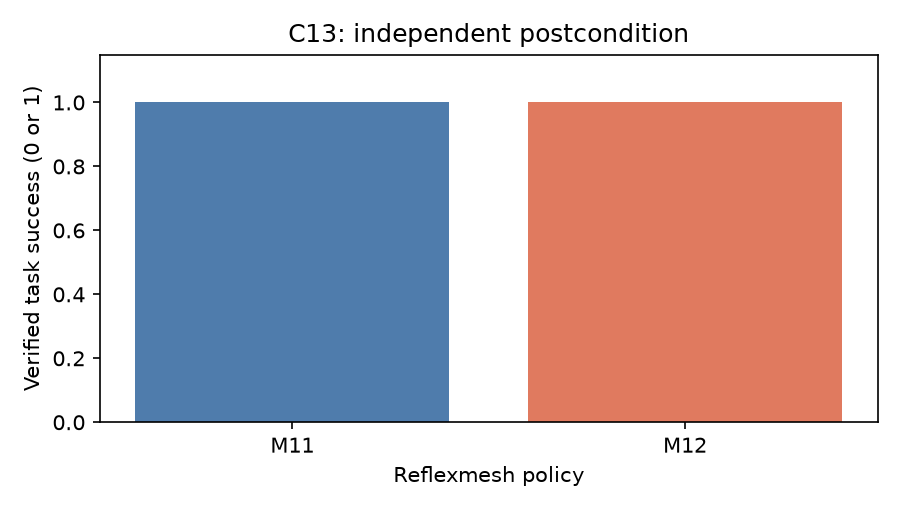

In [11]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Evidence analysis 12

Separate transfer episodes from the core matrix before calculating a headline score. This is evidence slice 12 in the deliberation study. Observation 12 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 12 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


In [12]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("State-of-the-art comparator runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


State-of-the-art comparator runs: 1
XGBoost task success: 1


### Evidence analysis 13

The final plot reports measured outcomes from this design and makes no biological claim. This is evidence slice 13 in the deliberation study. Observation 13 is interpreted alongside the committed task postcondition rather than treated as an isolated demonstration. Slice 13 is bounded by the named software cases, frozen artifacts, and evaluation protocol.


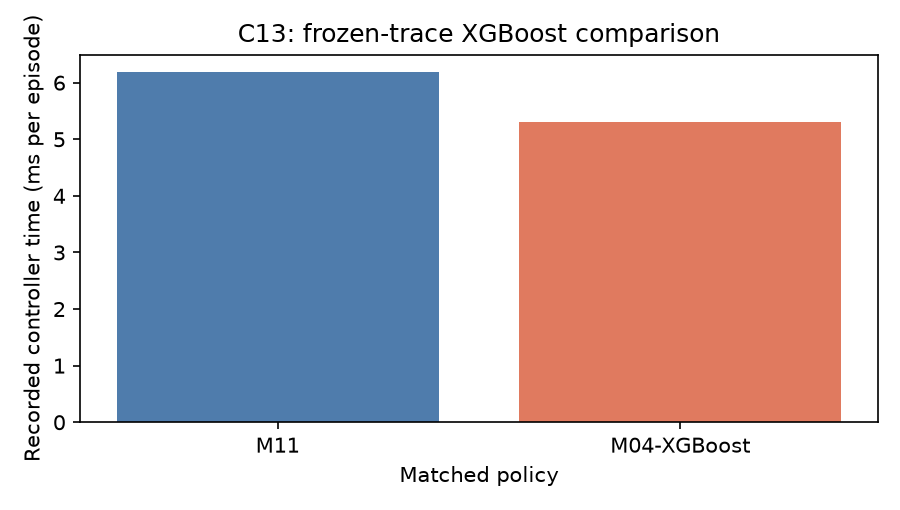

In [13]:
# Compare hash-verified canonical controller times under the same case, variant and seed.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Matched policy")
ax.set_title(f"{sample_case}: frozen-trace XGBoost comparison")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


## State of the art

Fixed rules, learned ranking, and delegated planning supply distinct comparison points. The relevant baseline is not a language model alone: it includes a guarded state machine that already solves every core episode at far lower decision latency. The proposition must beat that capable baseline on a task distribution where delegation has value.


## Beyond the state of the art

The benchmark tests the BS-1 hypothesis, but it was not designed to prove it. Treat the frozen index and research summary as the evidence boundary. An implemented mechanism does not establish efficacy. All core comparisons retain failures and include 1,200 episodes per method.

| Evidence | M12 | Comparator or ablation | Interpretation |
| --- | ---: | ---: | --- |
| Core success | 1,160 / 1,200 | M01: 1,200 / 1,200 | M12 is 40 episodes below the guarded finite-state baseline. |
| Decision latency p50 | 18.13 ms | M01: 0.022 ms | M12 adds controller cost. |
| Decision latency p95 | 158.97 ms | M01: 0.039 ms | Tail latency challenges a fast-control claim. |
| No-memory ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |
| No-effects ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |
| No-deferral ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |
| No-invalidation ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |

M12's forty failures occur in C07, long-job cancellation, across four variants, with zero successes in each affected cell. This localizes a repair target, but it narrows the claim. It does not show that persistent state, effect memory, or invalidation are ineffective generally. It shows they did not change success on this represented distribution under these implementations and protocol.

Ablation contrasts are exact for task success: paired differences are zero over 1,200 cells. The bootstrap interval is degenerate because seed-level outcomes do not vary. That is not a precision guarantee. Evidence is constrained by repeated deterministic outcomes and few independent task families. A stronger evaluation should vary environment transitions and planner outcomes by seed, preregister unseen cancellation and recovery families, and report uncertainty clustered by family.

M12 fails its current superiority criterion. It may still provide safety value through stale-plan invalidation or auditable effects, but those properties differ from task success. Follow-up work must measure independent postconditions and stale or unauthorized effects under matched compute budgets and paired state changes. M12 earns a positive claim only if it improves the success-cost frontier without weakening broker authority checks.

This result does not license a biological analogy. Neuroscience motivates a bounded fast/slow control question, while this benchmark measures software policies and controller costs. The proposal is a computational design, not a neural-circuit model. “Beyond the state of the art” names a method tier and does not mean that superiority is demonstrated. Preserve this negative result, repair cancellation, and evaluate varied held-out compositions before claiming benefit.

## Results

**Answer:** The committed results do not support a success or latency advantage for M12. Its core outcome is 1,160 of 1,200, versus 1,200 of 1,200 for M01; the four ablations match its task success. This is a negative result for the stated superiority hypothesis, not proof that the design can never help.


## Summary

A decisive follow-up needs held-out task families, variable seeds, explicit planner failures, resource changes during pending plans, paired compute budgets, and independent safety postconditions. Report task success and safety separately. Preserve the current evidence and do not convert the method-tier label into a claim of demonstrated novelty or biological equivalence.


## References

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [Asynchronous deep reinforcement learning](https://arxiv.org/abs/1711.06892)
- [Learning when to act](https://proceedings.mlr.press/v119/mozannar20b.html)
- [ACL 2025 related work](https://aclanthology.org/2025.acl-long.206/)
